# 第 3 章配套 Notebook：手算反向传播与脉冲阶跃函数零导数困境

[![Open In Colab (main)](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Casey-sketch-cyber/gnn2gsnn/blob/main/notion/notebooks/ch03_backprop_and_step_derivative.ipynb) （PR 审查期分支链接：[点此在 Colab 打开 gemini/deep-01 版](https://colab.research.google.com/github/Casey-sketch-cyber/gnn2gsnn/blob/gemini/deep-01/notion/notebooks/ch03_backprop_and_step_derivative.ipynb)）

> **运行环境**：仅需 Python ≥ 3.10、`numpy`、`matplotlib`，不需要 GPU，也不依赖 PyTorch 等深度学习框架。所有矩阵每一步的中间数值均直接打印并与第 3 章正文手算结果逐位核对一致。

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib

# 配置中文与负号显示（Windows / Linux / macOS / Colab 通用回退）
matplotlib.rcParams['font.sans-serif'] = ['Microsoft YaHei', 'SimHei', 'Noto Sans CJK SC', 'Arial Unicode MS', 'DejaVu Sans']
matplotlib.rcParams['axes.unicode_minus'] = False
np.set_printoptions(precision=6, suppress=True)
print("NumPy version:", np.__version__)


NumPy version: 2.5.5


## 1. 两层小网络完整手算前向与反向传播复现

复现第 3 章手算例 3.1：
- 输入 $\mathbf{x} = [1.0, 2.0]^\top$，真值标量 $y = 1.0$；
- 第 1 层：$W^{(1)} = \begin{bmatrix} 0.5 & 0.5 \\ 1.0 & -1.0 \end{bmatrix}, \mathbf{b}^{(1)} = [0.0, 0.0]^\top$，激活 $\mathbf{h} = \mathrm{ReLU}(\mathbf{z}^{(1)})$；
- 第 2 层：$W^{(2)} = [1.0, 2.0]$（形状 $1\times 2$），$b^{(2)} = 0.0$，预测 $\hat{y} = W^{(2)}\mathbf{h} + b^{(2)}$；
- 损失函数：$L = \frac{1}{2}(\hat{y} - y)^2$，学习率 $\eta = 0.1$。

In [2]:
x = np.array([1.0, 2.0])
y_true = 1.0

W1 = np.array([[0.5,  0.5],
               [1.0, -1.0]])  # shape (2, 2)
b1 = np.array([0.0, 0.0])     # shape (2,)
W2 = np.array([[1.0, 2.0]])   # shape (1, 2)
b2 = np.array([0.0])          # shape (1,)

# --- 前向计算 ---
z1 = W1 @ x + b1              # [1.5, -1.0]
h  = np.maximum(0.0, z1)      # [1.5,  0.0]  <-- 注意第 2 个神经元被 ReLU 截断为 0
y_hat = (W2 @ h + b2)[0]      # 1.5
loss = 0.5 * (y_hat - y_true) ** 2  # 0.5 * (0.5)^2 = 0.125

print(f"前向: z1 = {z1}, h = {h}, y_hat = {y_hat:.4f}, L = {loss:.6f}")
assert np.allclose(z1, [1.5, -1.0])
assert np.allclose(h, [1.5, 0.0])
assert np.isclose(y_hat, 1.5) and np.isclose(loss, 0.125)

# --- 反向传播（链式法则逐层求偏导） ---
dL_dyhat = y_hat - y_true                 # 0.5
dL_dW2   = dL_dyhat * h[None, :]          # [[0.75, 0.0]]
dL_db2   = np.array([dL_dyhat])           # [0.5]

dL_dh    = W2[0] * dL_dyhat               # [0.5, 1.0]
relu_grad = (z1 > 0).astype(float)        # [1.0, 0.0]  <-- z1[1]=-1<0 处导数为 0！
dL_dz1   = dL_dh * relu_grad              # [0.5, 0.0]
dL_dW1   = np.outer(dL_dz1, x)            # [[0.5, 1.0], [0.0, 0.0]]
dL_db1   = dL_dz1                         # [0.5, 0.0]

print("反向梯度:")
print("  dL/dy_hat =", dL_dyhat)
print("  dL/dW2    =", dL_dW2)
print("  dL/dh     =", dL_dh)
print("  ReLU'(z1) =", relu_grad)
print("  dL/dz1    =", dL_dz1)
print("  dL/dW1    =\n", dL_dW1)

# --- 中心差分数值梯度检验（验证手算梯度 100% 正确） ---
eps_fd = 1e-6
num_dW1 = np.zeros_like(W1)
for i in range(2):
    for j in range(2):
        W_pos = W1.copy(); W_pos[i, j] += eps_fd
        W_neg = W1.copy(); W_neg[i, j] -= eps_fd
        L_pos = 0.5 * ((W2 @ np.maximum(0.0, W_pos @ x + b1) + b2)[0] - y_true) ** 2
        L_neg = 0.5 * ((W2 @ np.maximum(0.0, W_neg @ x + b1) + b2)[0] - y_true) ** 2
        num_dW1[i, j] = (L_pos - L_neg) / (2 * eps_fd)
assert np.allclose(dL_dW1, num_dW1)
print("中心差分数值检验通过！最大梯度偏差 =", np.max(np.abs(dL_dW1 - num_dW1)))

# --- 执行一步梯度下降（eta = 0.1） ---
eta = 0.1
W1_new = W1 - eta * dL_dW1
b1_new = b1 - eta * dL_db1
W2_new = W2 - eta * dL_dW2
b2_new = b2 - eta * dL_db2

h_new = np.maximum(0.0, W1_new @ x + b1_new)
yhat_new = (W2_new @ h_new + b2_new)[0]
loss_new = 0.5 * (yhat_new - y_true) ** 2
print(f"\n更新一步后: h_new = {h_new}, y_hat_new = {yhat_new:.6f}, L_new = {loss_new:.6f} (原 L = {loss:.6f})")
assert np.isclose(yhat_new, 1.06) and np.isclose(loss_new, 0.0018)
assert loss_new < loss


前向: z1 = [ 1.5 -1. ], h = [1.5 0. ], y_hat = 1.5000, L = 0.125000
反向梯度:
  dL/dy_hat = 0.5
  dL/dW2    = [[0.75 0.  ]]
  dL/dh     = [0.5 1. ]
  ReLU'(z1) = [1. 0.]
  dL/dz1    = [0.5 0. ]
  dL/dW1    =
 [[0.5 1. ]
 [0.  0. ]]
中心差分数值检验通过！最大梯度偏差 = 1.9816592811139344e-11

更新一步后: h_new = [1.2 0. ], y_hat_new = 1.060000, L_new = 0.001800 (原 L = 0.125000)


## 2. 为什么脉冲网络的阶跃函数 $H(u)$ 让标准反向传播彻底停摆？

参照 Neftci 等（IEEE SPM 2019, Section IV & Fig. 3）：把隐藏层激活从 $\mathrm{ReLU}$ 换成阈值为 $\theta = 1.0$ 的脉冲阶跃函数 $s = H(z - \theta)$。对于所有 $z \neq \theta$，真实导数 $H'(z - \theta) = 0$，链式法则乘上 0 后上游权重梯度恒为 0！

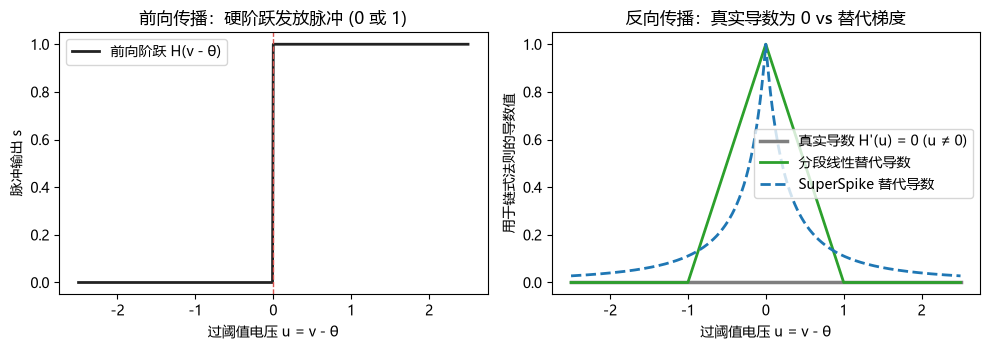

目标 y=0.2 时预测误差 = 0.8
用真实阶跃导数算出的 dL/dW1 (全 0，无法更新):
 [[0. 0.]
 [0. 0.]]
用分段线性替代导数算出的近似 dL/dW1:
 [[0.4 0.8]
 [0.  0. ]]


In [3]:
theta = 1.0
u_grid = np.linspace(-2.5, 2.5, 501)  # u = v - theta
heaviside = (u_grid >= 0).astype(float)
# 除 u=0 点无定义外，处处导数为 0
true_deriv = np.zeros_like(u_grid)
true_deriv[np.isclose(u_grid, 0.0)] = np.nan

# 常见替代导数（Surrogate Derivatives，Neftci et al. 2019 Fig. 3）：
# 1) 分段线性（矩形/三角窗）：max(0, 1 - |u|)
surr_pwl = np.maximum(0.0, 1.0 - np.abs(u_grid))
# 2) SuperSpike 快速 Sigmoid 导数：1 / (1 + beta * |u|)^2 (beta=2)
surr_superspike = 1.0 / (1.0 + 2.0 * np.abs(u_grid)) ** 2

fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
axes[0].plot(u_grid, heaviside, color="#222", lw=2, label="前向阶跃 H(v - θ)")
axes[0].axvline(0, color="#d9534f", ls="--", lw=1)
axes[0].set_title("前向传播：硬阶跃发放脉冲 (0 或 1)")
axes[0].set_xlabel("过阈值电压 u = v - θ")
axes[0].set_ylabel("脉冲输出 s")
axes[0].legend()

axes[1].plot(u_grid, np.zeros_like(u_grid), color="#7f7f7f", lw=2.5, label="真实导数 H'(u) = 0 (u ≠ 0)")
axes[1].plot(u_grid, surr_pwl, color="#2ca02c", lw=2, label="分段线性替代导数")
axes[1].plot(u_grid, surr_superspike, color="#1f77b4", ls="--", lw=2, label="SuperSpike 替代导数")
axes[1].set_title("反向传播：真实导数为 0 vs 替代梯度")
axes[1].set_xlabel("过阈值电压 u = v - θ")
axes[1].set_ylabel("用于链式法则的导数值")
axes[1].legend()
plt.tight_layout()
plt.show()

# 对比在同一网络上：真实阶跃导数（权重纹丝不动）vs 替代导数
z1_spike = W1 @ x + b1 - theta     # [0.5, -2.0]
s_hidden = (z1_spike >= 0).astype(float)  # [1.0, 0.0]
yhat_sp  = (W2 @ s_hidden + b2)[0]        # 1.0 (若设目标 y_target = 0.2，误差非零)
err_sp   = yhat_sp - 0.2                  # 0.8
grad_W1_true = np.outer((W2[0] * err_sp) * 0.0, x)  # 真实导数处处为 0！
grad_W1_surr = np.outer((W2[0] * err_sp) * np.maximum(0.0, 1.0 - np.abs(z1_spike)), x)
print("目标 y=0.2 时预测误差 =", err_sp)
print("用真实阶跃导数算出的 dL/dW1 (全 0，无法更新):\n", grad_W1_true)
print("用分段线性替代导数算出的近似 dL/dW1:\n", grad_W1_surr)
